# Perform analysis for peak variation over time bining.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import math
import os

from rfi_pipeline import (analyze_time_bins, bin_spectrum, detrend_spectrum,
                          analyze_binned_spectrum, assign_peak_groups)


import h5py
import xarray as xr
import pandas as pd


import scienceplots
plt.style.use(['science', 'no-latex'])


# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [2]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = True  # Set to True to save the plots, False to just display them


In [3]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e3  # kHz
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [4]:
# select a scan
scan = 'scan/001/P1_ND0'
scan_name = scan.replace('/', '_')
data = datasets[scan]

# scan type and polarization from the group name, e.g. 'scan/001/P1_ND0'
SCAN_TYPES = {'000': 'Azimuth-Scan', '001': 'Elevation-Scan'}
POLARIZATIONS = {'P0': 'Horizontal', 'P1': 'Vertical'}
scan_id, pol_nd = scan.split('/')[1:]
scan_type = SCAN_TYPES[scan_id]
polarization = POLARIZATIONS[pol_nd.split('_')[0]]
scan_label = f'{scan_type} | {polarization} pol.'

def add_scan_info(df):
    """Tag a results table with the scan it came from (as the first columns)."""
    info = {'scan': scan, 'scan_type': scan_type, 'polarization': polarization}
    df = df.drop(columns=list(info), errors='ignore')
    for i, (col, val) in enumerate(info.items()):
        df.insert(i, col, val)
    return df

spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra  # counts
frequency_khz = data['frequency'].values
time = data['time'].values

print(scan_label)
print(spectrum.shape, f"cadence = {np.median(np.diff(time)):.3f} s")

Elevation-Scan | Vertical pol.
(636, 63877) cadence = 0.153 s


# Time binning

The spectrum is split into consecutive, non-overlapping blocks and each block is averaged in linear power. Peak detection runs at both levels: high-level peaks use 3σ, then low-level peaks use 5σ after high-level features are masked. The `detection_level` column distinguishes the two.

Frequency metrics (`f_peak`, `fc`, and bandwidths) are in **kHz**. `RBW` is the dimensionless ratio `B99 / FWHM`. `channel_spacing` is the frequency-channel spacing in **kHz**. Peak amplitudes and integrated amplitude `A` are in **counts**. The shape metric `S` and bandwidth ratios are dimensionless.

* `bin_size=6` → 6 spectra per bin (≈ 0.92 s, 105 bins)
* `bin_seconds=6` → 6 s per bin (≈ 39 spectra, 16 bins)

Note: `analyze_time_bins(spectrum, freq, time_bins=[...])` on its own takes single rows `spectrum[t]`; here `analyze_binned_spectrum` averages first.

In [5]:
BIN_SIZE = 6          # spectra per bin  (or use bin_seconds=6 instead)

SIGMA_HIGH = float(input("High-level sigma [3]: ") or 3)
SIGMA_LOW = float(input("Low-level sigma [5]: ") or 5)
SIGMA_VALUES = {"high": SIGMA_HIGH, "low": SIGMA_LOW}

binned, bin_info = bin_spectrum(spectrum, time, bin_size=BIN_SIZE)
print(binned.shape)
bin_info.head()

(106, 63877)


,time_bin,t_start,t_end,t_mid,row_start,row_end,n_spectra,mean,std,skewness,kurtosis
0,0,1.678547e+09,1.678547e+09,1.678547e+09,0,5,6,2.050801e+11,7.788435e+10,-0.246916,3.802106
1,1,1.678547e+09,1.678547e+09,1.678547e+09,6,11,6,2.047153e+11,7.775287e+10,-0.246040,3.801526
2,2,1.678547e+09,1.678547e+09,1.678547e+09,12,17,6,2.055781e+11,7.806005e+10,-0.247006,3.809688
3,3,1.678547e+09,1.678547e+09,1.678547e+09,18,23,6,2.045494e+11,7.769416e+10,-0.243702,3.834582
4,4,1.678547e+09,1.678547e+09,1.678547e+09,24,29,6,2.046401e+11,7.771185e+10,-0.244861,3.834451


In [6]:
# ~10 s per bin; detect high peaks, then low peaks using their prompted sigma values
results_binned = analyze_binned_spectrum(
    spectrum, frequency_khz, time,
    bin_size=BIN_SIZE, rf_level="both", sigma_values=SIGMA_VALUES
)

# Match peaks across bins using the existing 2 MHz tolerance (2000 kHz).
results_binned = assign_peak_groups(
    results_binned, frequency_column="f_peak", tolerance_mhz=2000.0
).rename(columns={"peak_reference_MHz": "peak_reference_kHz"})
results_binned = add_scan_info(results_binned)


results_binned.head()

,scan,scan_type,polarization,time_bin,detection_level,peak_index,start_index,end_index,peak_height,detection_threshold,...,row_start,row_end,n_spectra,mean,std,skewness,kurtosis,t_rel,peak_group,peak_reference_kHz
0,scan/001/P1_ND0,Elevation-Scan,Vertical,0,high,1007,903,1257,3.713471e+11,5.735958e+10,...,0,5,6,2.050801e+11,7.788435e+10,-0.246916,3.802106,0.383479,0,1.819628e+06
1,scan/001/P1_ND0,Elevation-Scan,Vertical,0,high,7866,7782,7945,7.828172e+11,5.735958e+10,...,0,5,6,2.050801e+11,7.788435e+10,-0.246916,3.802106,0.383479,7,2.002796e+06
2,scan/001/P1_ND0,Elevation-Scan,Vertical,0,high,14142,14131,14149,8.378718e+10,5.735958e+10,...,0,5,6,2.050801e+11,7.788435e+10,-0.246916,3.802106,0.383479,12,2.172293e+06
3,scan/001/P1_ND0,Elevation-Scan,Vertical,0,high,15250,15165,15329,7.019643e+11,5.735958e+10,...,0,5,6,2.050801e+11,7.788435e+10,-0.246916,3.802106,0.383479,15,2.199917e+06
4,scan/001/P1_ND0,Elevation-Scan,Vertical,0,high,26188,26164,26208,1.945587e+11,5.735958e+10,...,0,5,6,2.050801e+11,7.788435e+10,-0.246916,3.802106,0.383479,62,2.492353e+06


`f_peak` is the strongest channel frequency and `fc` is the power-weighted center; both are reported in kHz. For an asymmetric feature, `fc` shifts toward the side with more power.

# Peaks found in each bin

In [7]:
n_bins = results_binned['time_bin'].nunique()
occupancy = (results_binned.groupby('peak_group')
             .agg(f_ref_kHz=('peak_reference_kHz', 'first'),
                  detection_level=('detection_level', 'first'),
                  n_bins_detected=('time_bin', 'nunique'))
             .assign(fraction=lambda d: d['n_bins_detected'] / n_bins)
             .sort_values('n_bins_detected', ascending=False)
             .pipe(add_scan_info))
occupancy

,scan,scan_type,polarization,f_ref_kHz,detection_level,n_bins_detected,fraction
peak_group,,,,,,,
0,scan/001/P1_ND0,Elevation-Scan,Vertical,1.819628e+06,high,106,1.000000
7,scan/001/P1_ND0,Elevation-Scan,Vertical,2.002796e+06,high,106,1.000000
15,scan/001/P1_ND0,Elevation-Scan,Vertical,2.199917e+06,high,106,1.000000
62,scan/001/P1_ND0,Elevation-Scan,Vertical,2.492353e+06,high,106,1.000000
41,scan/001/P1_ND0,Elevation-Scan,Vertical,2.379948e+06,low,102,0.962264
...,...,...,...,...,...,...,...
77,scan/001/P1_ND0,Elevation-Scan,Vertical,2.751158e+06,low,1,0.009434
78,scan/001/P1_ND0,Elevation-Scan,Vertical,2.754068e+06,low,1,0.009434
79,scan/001/P1_ND0,Elevation-Scan,Vertical,2.803362e+06,low,1,0.009434


In [8]:
occupancy[:12]

,scan,scan_type,polarization,f_ref_kHz,detection_level,n_bins_detected,fraction
peak_group,,,,,,,
0,scan/001/P1_ND0,Elevation-Scan,Vertical,1.819628e+06,high,106,1.000000
7,scan/001/P1_ND0,Elevation-Scan,Vertical,2.002796e+06,high,106,1.000000
15,scan/001/P1_ND0,Elevation-Scan,Vertical,2.199917e+06,high,106,1.000000
62,scan/001/P1_ND0,Elevation-Scan,Vertical,2.492353e+06,high,106,1.000000
41,scan/001/P1_ND0,Elevation-Scan,Vertical,2.379948e+06,low,102,0.962264
37,scan/001/P1_ND0,Elevation-Scan,Vertical,2.362911e+06,low,99,0.933962
14,scan/001/P1_ND0,Elevation-Scan,Vertical,2.184349e+06,low,84,0.792453
12,scan/001/P1_ND0,Elevation-Scan,Vertical,2.172293e+06,high,76,0.716981
9,scan/001/P1_ND0,Elevation-Scan,Vertical,2.146524e+06,low,71,0.669811


# Variation of x = [fc, B99, FWHM, B10, B20, B30, RBW, A, S] per peak

In [9]:
METRICS = ['fc', 'B99', 'FWHM', 'B10', 'B20', 'B30', 'RBW', 'A', 'S']
FREQUENCY_METRICS = {'fc', 'B99', 'FWHM', 'B10', 'B20', 'B30'}

def cv(x):
    m = x.mean()
    return x.std() / abs(m) if m != 0 else np.nan

# one row per peak, mean / std / CV of each metric over the bins
# (keep the strongest detection when a group has 2 peaks in the same bin)
per_bin = (results_binned.sort_values('peak_height', ascending=False)
           .drop_duplicates(['peak_group', 'time_bin']))

variation = per_bin.groupby('peak_group')[METRICS].agg(['mean', 'std', cv])
variation.insert(0, ('scan_type', ''), scan_type)
variation.insert(1, ('polarization', ''), polarization)
variation.insert(2, ('detection_level', ''), per_bin.groupby('peak_group')['detection_level'].first())
variation.insert(3, ('f_ref_kHz', ''), per_bin.groupby('peak_group')['peak_reference_kHz'].first())
variation.insert(4, ('n_bins', ''), per_bin.groupby('peak_group')['time_bin'].nunique())
variation



scan_type polarization detection_level     f_ref_kHz n_bins  \
                                                                               
peak_group                                                                     
0           Elevation-Scan     Vertical            high  1.819628e+06    106   
1           Elevation-Scan     Vertical             low  1.846598e+06      3   
2           Elevation-Scan     Vertical             low  1.873568e+06      2   
3           Elevation-Scan     Vertical             low  1.875650e+06      1   
4           Elevation-Scan     Vertical             low  1.879816e+06      1   
...                    ...          ...             ...           ...    ...   
77          Elevation-Scan     Vertical             low  2.751158e+06      1   
78          Elevation-Scan     Vertical             low  2.754068e+06      1   
79          Elevation-Scan     Vertical             low  2.803362e+06      1   
80          Elevation-Scan     Vertical             low  2.835352e+06      1   
81          Elevation-Scan     Vertical             low  2.863096e+06      1   

                      fc                                 B99              ...  \
                    mean         std        cv          mean         std  ...   
peak_group                                                                ...   
0           1.820480e+06   50.634009  0.000028   8203.830359  228.202580  ...   
1           1.845962e+06  279.814439  0.000152  11277.516683  415.685328  ...   
2           1.873227e+06  517.797914  0.000276   1375.198364  849.680466  ...   
3           1.875778e+06         NaN       NaN    400.543213         NaN  ...   
4           1.879873e+06         NaN       NaN    267.028809         NaN  ...   
...                  ...         ...       ...           ...         ...  ...   
77          2.750971e+06         NaN       NaN    453.948975         NaN  ...   
78          2.753931e+06         NaN       NaN   1522.064209         NaN  ...   
79          2.803100e+06         NaN       NaN    881.195068         NaN  ...   
80          2.835296e+06         NaN       NaN    133.514404         NaN  ...   
81          2.863088e+06         NaN       NaN    240.325928         NaN  ...   

                 B30        RBW                                  A  \
                  cv       mean        std        cv          mean   
peak_group                                                           
0           0.041255  18.664221   0.649078  0.034777  1.300555e+13   
1           0.037655   3.168973   1.103856  0.348332  2.326923e+12   
2           0.586720  34.296653  24.150155  0.704155  1.287766e+11   
3                NaN  11.156656        NaN       NaN  6.165373e+10   
4                NaN   5.541017        NaN       NaN  4.538954e+10   
...              ...        ...        ...       ...           ...   
77               NaN   9.182052        NaN       NaN  2.087849e+11   
78               NaN  20.183138        NaN       NaN  2.122035e+11   
79               NaN  23.755247        NaN       NaN  3.308769e+11   
80               NaN   1.261985        NaN       NaN  9.768828e+10   
81               NaN   3.013113        NaN       NaN  1.238752e+11   

                                           S                      
                     std        cv      mean       std        cv  
peak_group                                                        
0           7.488050e+10  0.005758  1.290355  0.045167  0.035003  
1           5.885138e+10  0.025292 -0.269000  0.166480  0.618885  
2           6.449524e+10  0.500830  0.082555  0.321890  3.899086  
3                    NaN       NaN  0.647464       NaN       NaN  
4                    NaN       NaN  0.705064       NaN       NaN  
...                  ...       ...       ...       ...       ...  
77                   NaN       NaN -0.014066       NaN       NaN  
78                   NaN       NaN -0.144723       NaN       NaN  
79                   NaN       NaN -0.12865

In [10]:
# save as dataframe
# save the dataframes of metrics vs frequency
if to_save:
    full_path = os.path.join(dirname, scan_name)
    os.makedirs(full_path, exist_ok=True)
    metric_time_summary = variation.to_csv(f'{full_path}/metrics_time_summary_{scan_name}.csv')

In [11]:
def plot_peak_metrics_vs_time(per_bin, group, metrics=METRICS, x_col='t_rel'):
    """3x3 panel: each metric of one peak group vs bin time."""
    d = per_bin[per_bin['peak_group'] == group].sort_values(x_col)
    f_ref = d['peak_reference_kHz'].iloc[0]
    level = d['detection_level'].iloc[0]

    fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
    for ax, metric in zip(axes.flat, metrics):
        ax.plot(d[x_col], d[metric], 'o-', ms=3, lw=1)
        ax.axhline(d[metric].median(), color='gray', ls='--', lw=0.8)
        unit = 'kHz' if metric in FREQUENCY_METRICS else 'counts' if metric == 'A' else ''
        ax.set_ylabel(f'{metric} [{unit}]' if unit else metric)
    for ax in axes[-1]:
        ax.set_xlabel('Time since start [s]')
    fig.suptitle(f'{scan_name} ({scan_label}) | {level}-level peak {group} @ {f_ref:.2f} kHz | '
                 f'{BIN_SIZE} spectra/bin | detected in {d["time_bin"].nunique()}/{n_bins} bins')
    fig.tight_layout()
    return fig

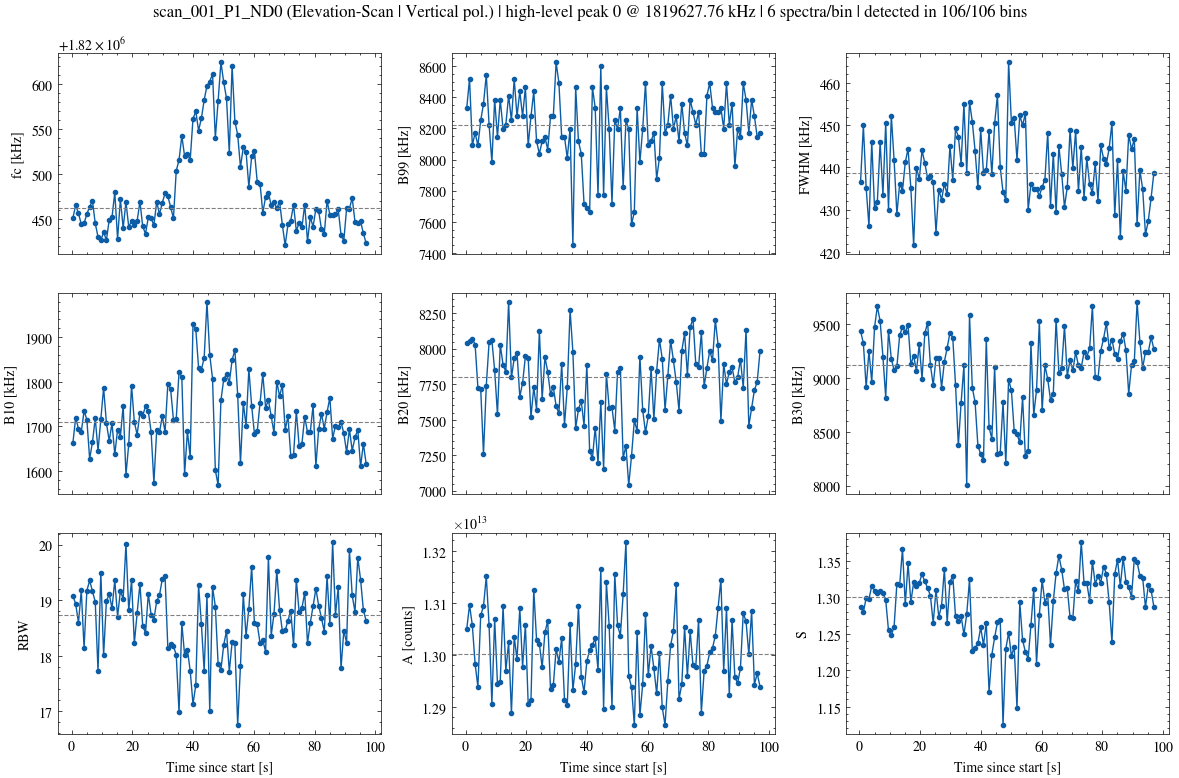

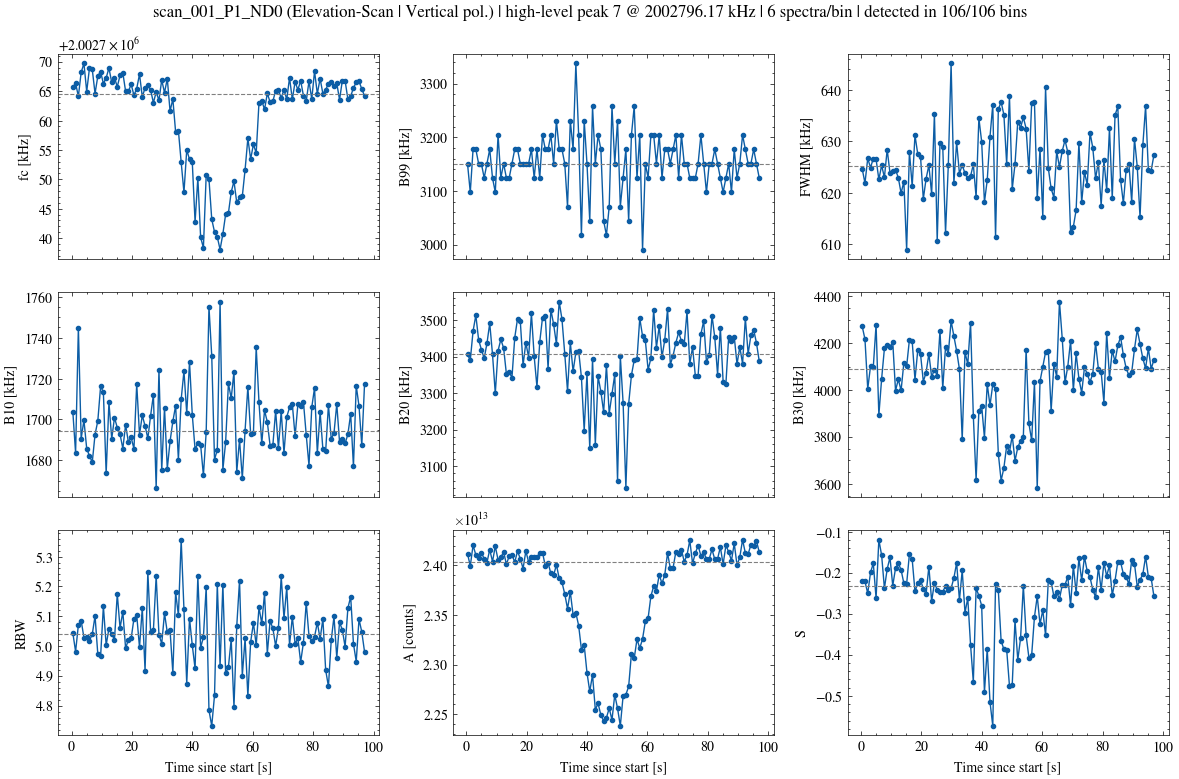

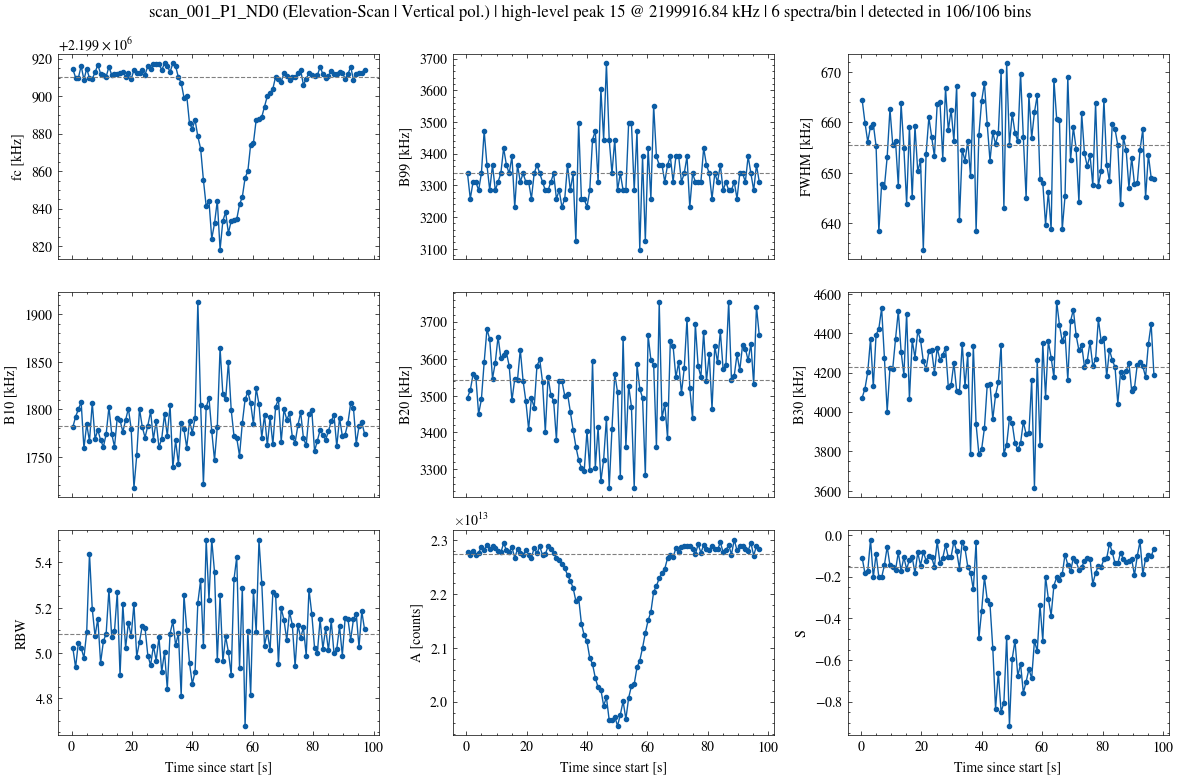

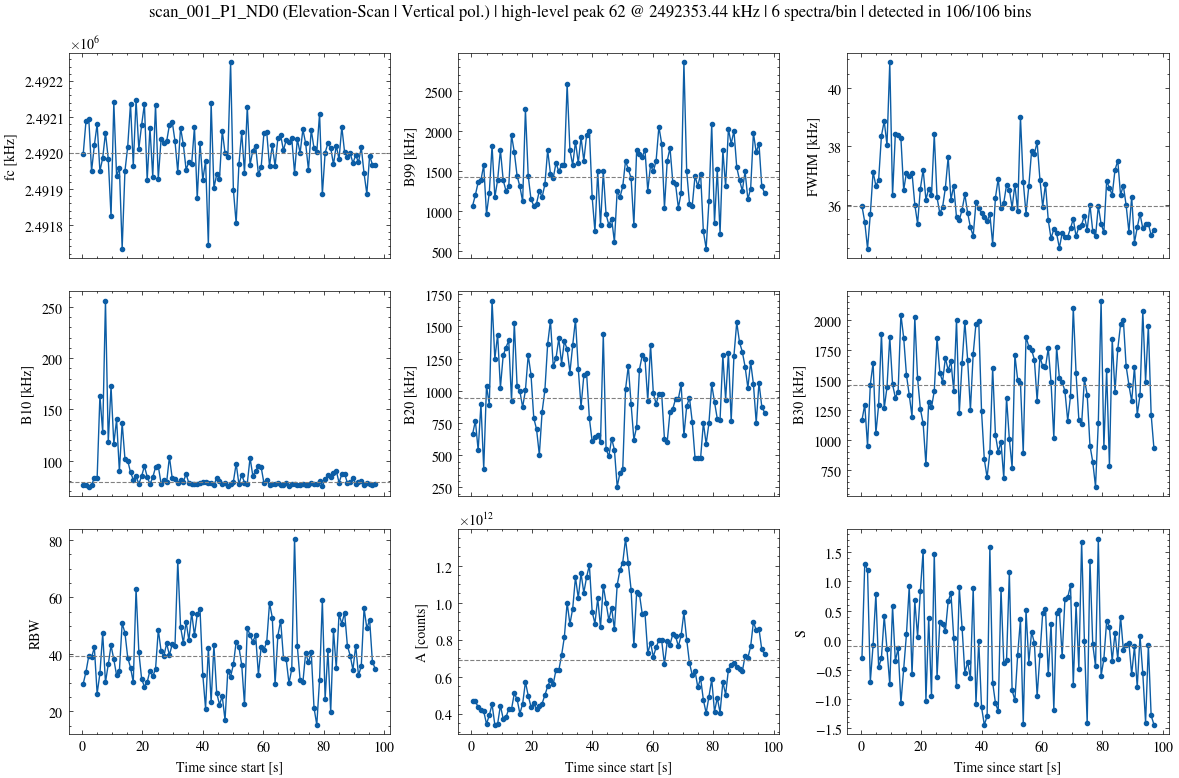

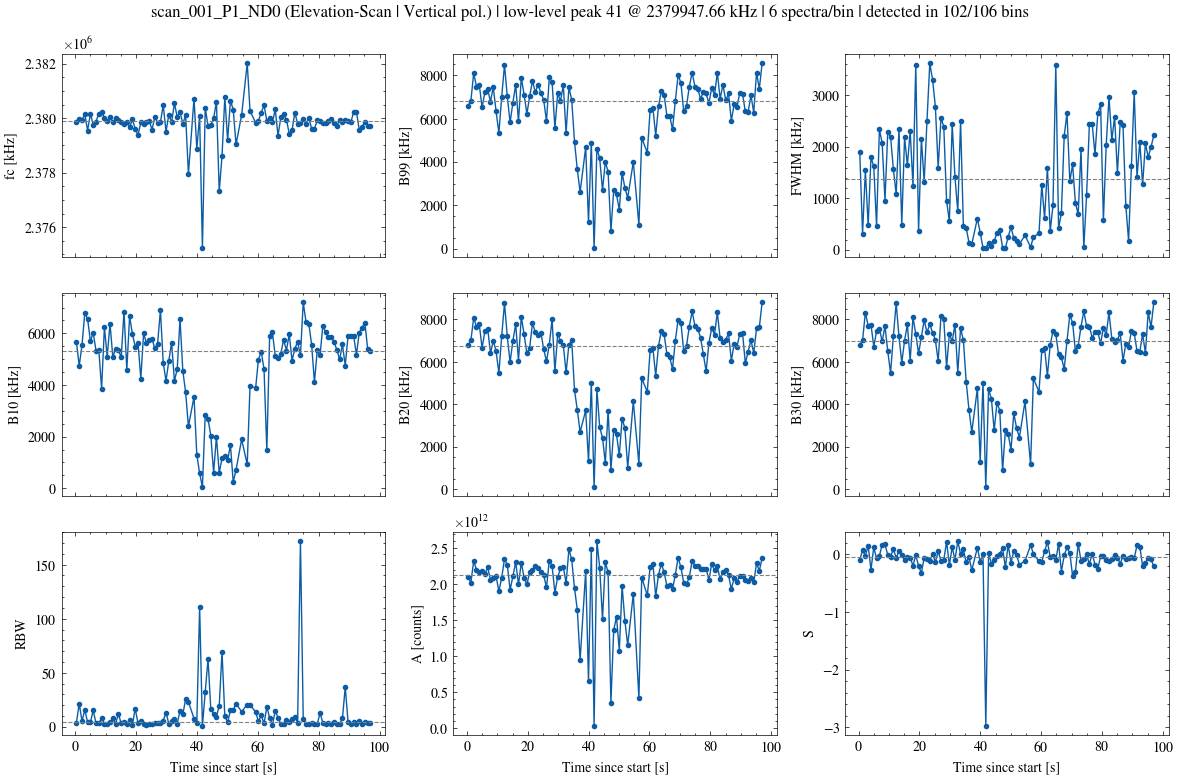

In [12]:
# plot the peaks detected in most bins
for g in occupancy.index[:5]:
    fig = plot_peak_metrics_vs_time(per_bin, g)
    if to_save:
        os.makedirs(full_path, exist_ok=True)
        fig.savefig(f'{full_path}/metrics_vs_time_{scan_name}_peak{g}.pdf', bbox_inches='tight')
        fig.savefig(f'{full_path}/metrics_vs_time_{scan_name}_peak{g}.png', bbox_inches='tight')
    plt.show()



In [13]:
# # plot the peaks detected in most bins
# for g in occupancy.index[:5]:
#     fig = plot_peak_metrics_vs_time(per_bin, g)
#     if to_save:
#         full_path = os.path.join(dirname, scan_name)
#         os.makedirs(full_path, exist_ok=True)
#         fig.savefig(os.path.join(full_path, f'metrics_vs_time_{scan_name}_peak{g}.pdf'), bbox_inches='tight')
#         fig.savefig(os.path.join(full_path, f'metrics_vs_time_{scan_name}_peak{g}.png'), bbox_inches='tight')
#     plt.show()


In [14]:
# perform the analysis on the time-averaged spectrum, retaining high/low labels
mean_spec = spectrum.mean(axis=0, keepdims=True)
res_full = analyze_time_bins(
    mean_spec, frequency_khz, time_bins=[0], rf_level="both",
    sigma_values=SIGMA_VALUES
)
res_full = add_scan_info(res_full)
p_detrend, _ = detrend_spectrum(mean_spec[0], frequency_khz)

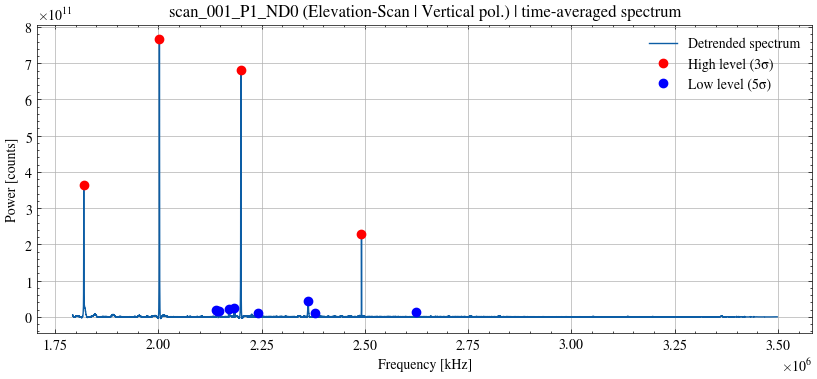

In [15]:
# Plot detected high- and low-level peaks on the time-averaged spectrum
high_peaks = res_full.loc[res_full['detection_level'] == 'high', 'peak_index'].astype(int)
low_peaks = res_full.loc[res_full['detection_level'] == 'low', 'peak_index'].astype(int)

plt.figure(figsize=(10, 4))
plt.plot(frequency_khz, p_detrend, label='Detrended spectrum')
plt.plot(frequency_khz[high_peaks], p_detrend[high_peaks], 'ro', label='High level (3σ)')
plt.plot(frequency_khz[low_peaks], p_detrend[low_peaks], 'bo', label='Low level (5σ)')
plt.xlabel('Frequency [kHz]')
plt.ylabel('Power [counts]')
plt.title(f'{scan_name} ({scan_label}) | time-averaged spectrum')
plt.grid()
plt.legend()

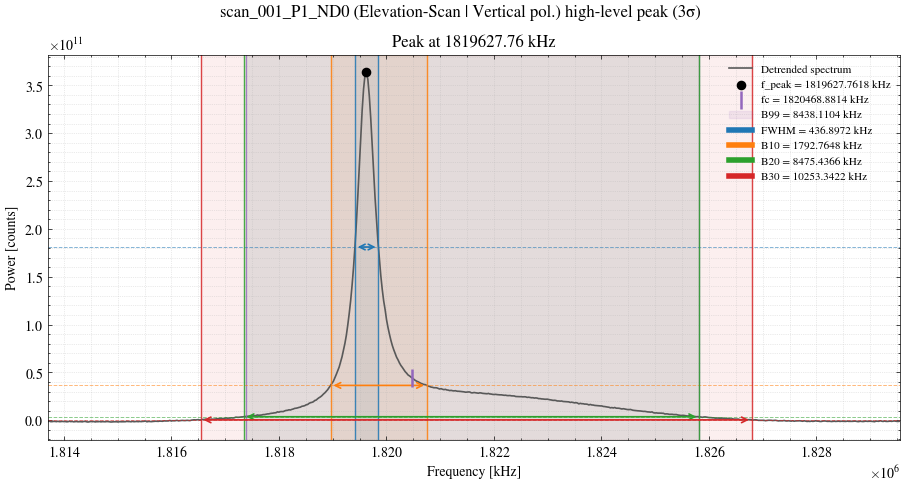

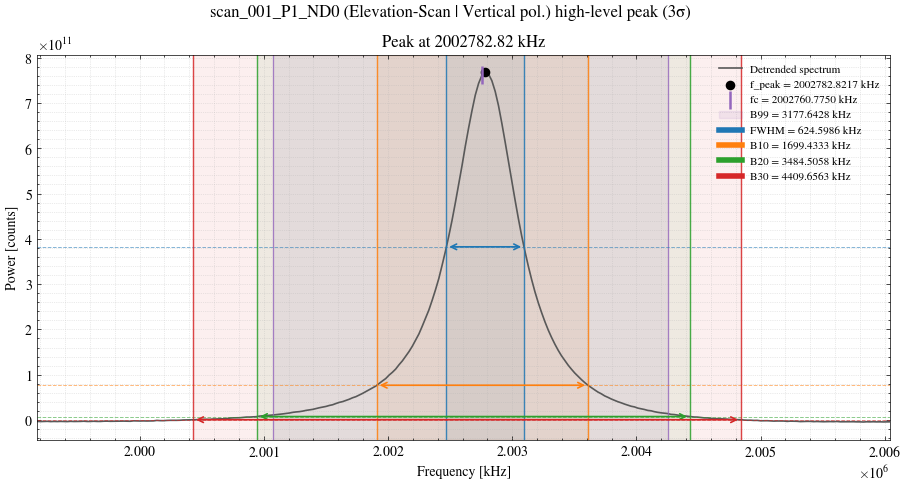

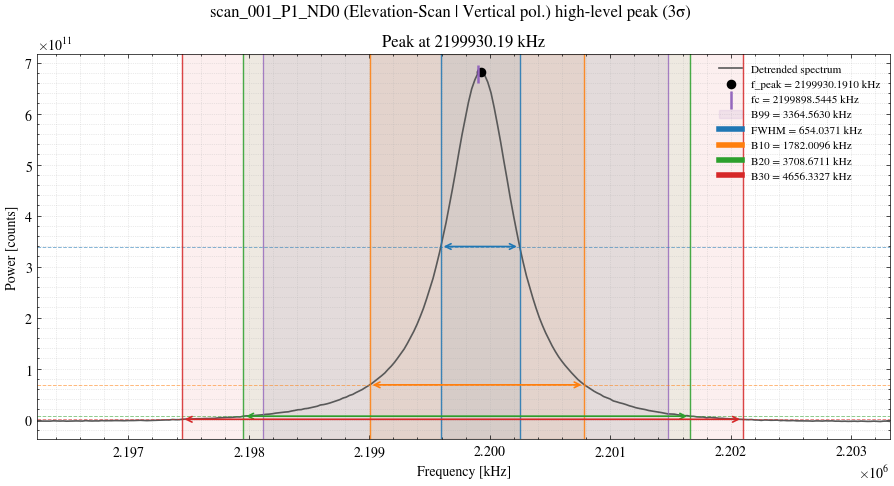

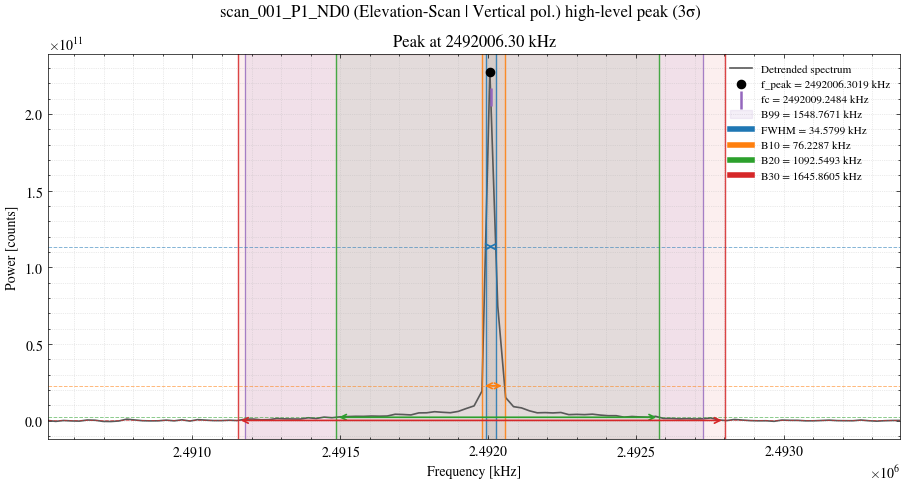

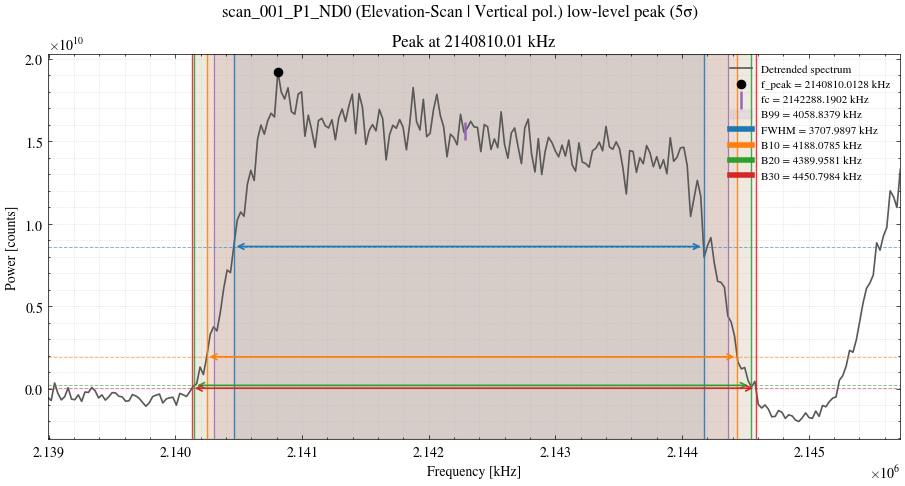

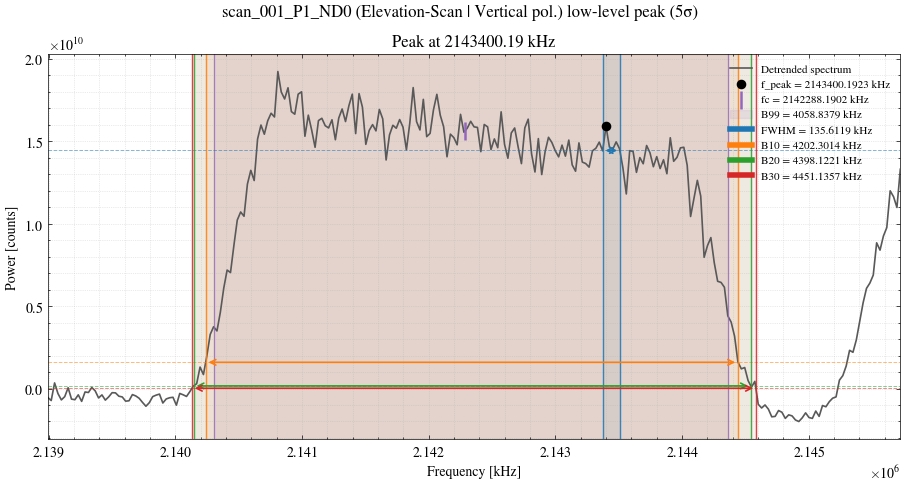

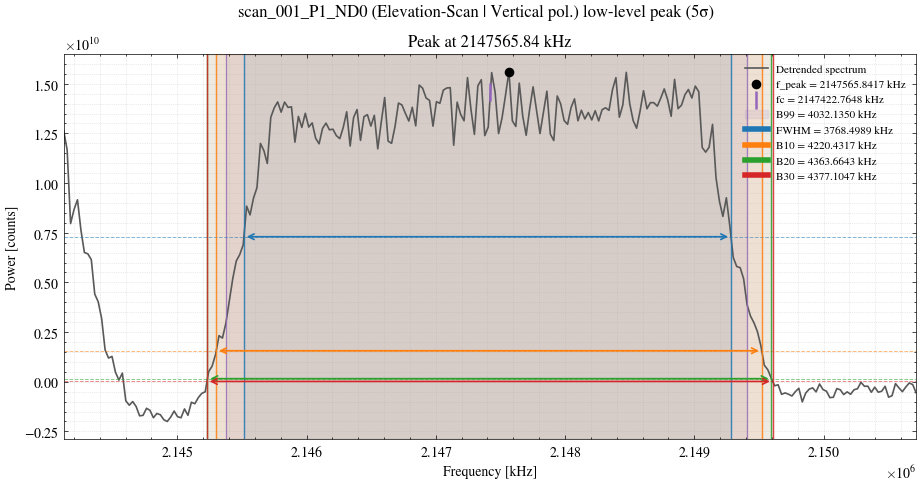

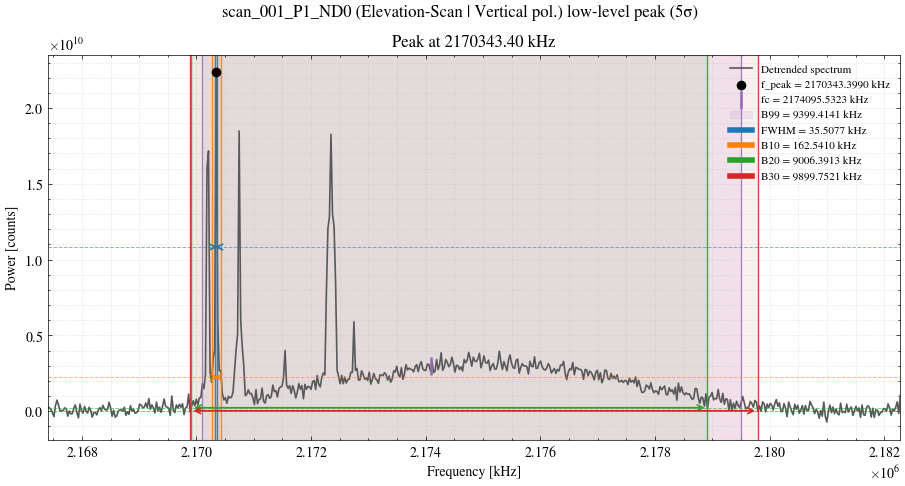

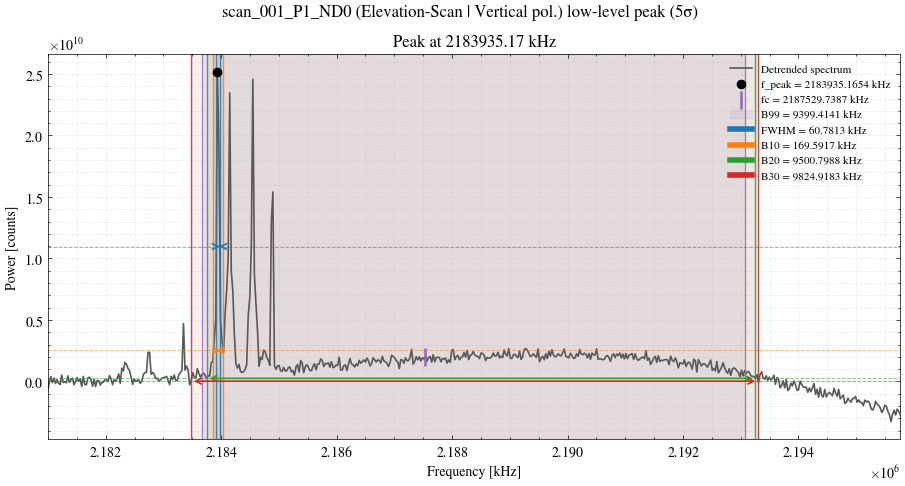

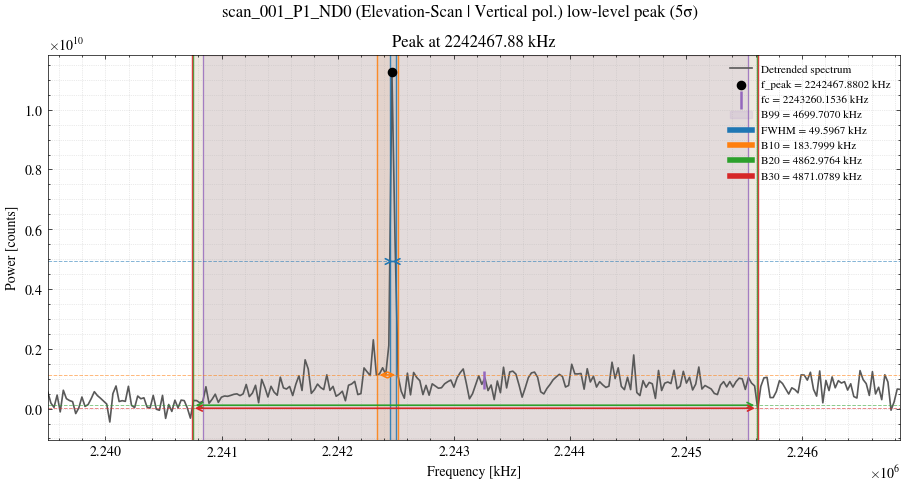

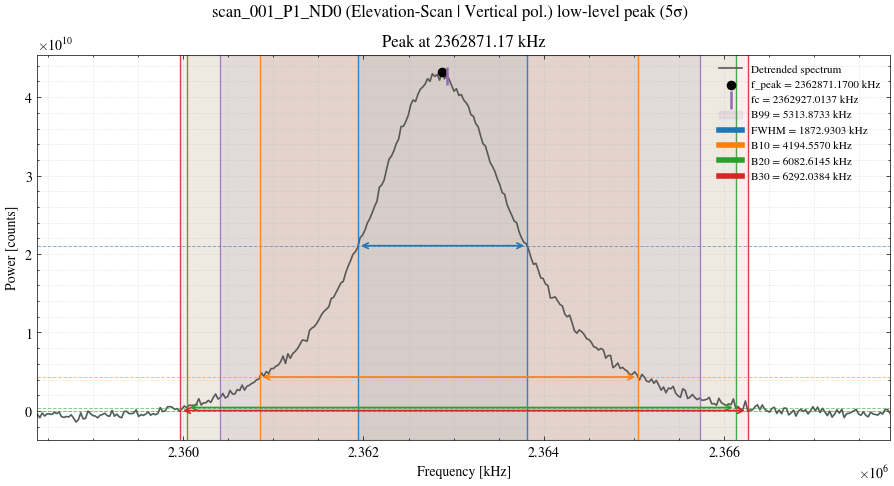

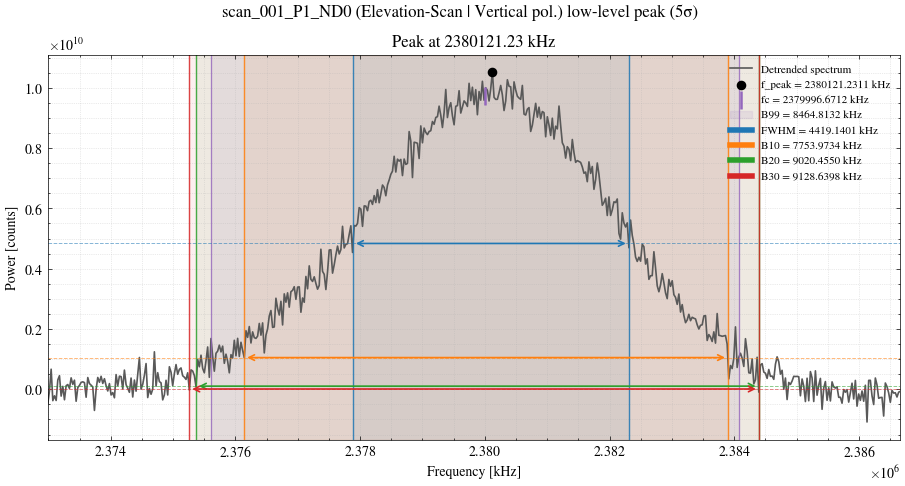

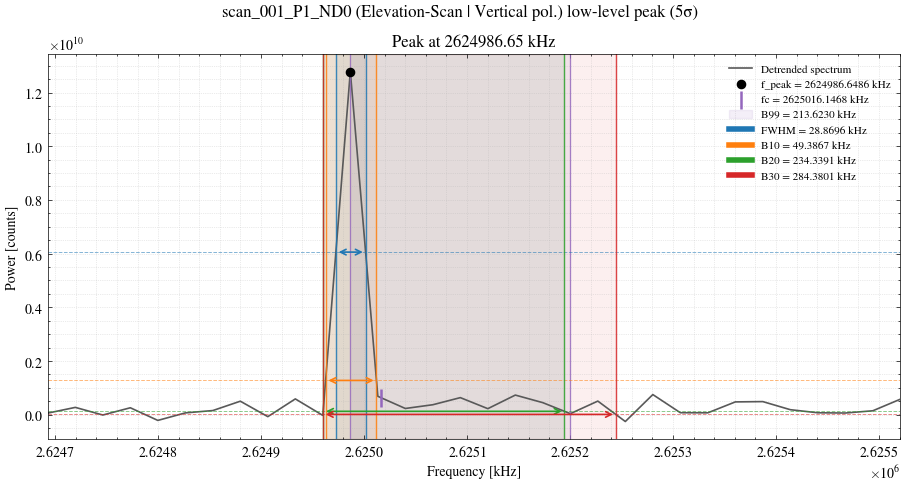

In [16]:
# Perform the analysis on the time-averaged spectrum for each peak detected

if res_full.empty:
    print("No peaks detected in the time-averaged spectrum.")
else:
    for _, peak in res_full.iterrows():
        peak_index = int(peak['peak_index'])
        start_index = int(peak['start_index'])
        end_index = int(peak['end_index'])
        pad = max(10, int(0.25 * (end_index - start_index + 1)))
        lo = max(0, start_index - pad)
        hi = min(len(frequency_khz), end_index + pad + 1)
        detection_level = peak['detection_level']
        sigma = 3 if detection_level == 'high' else 5

        fig, ax = plt.subplots(figsize=(11, 5))
        fig.suptitle(f"{scan_name} ({scan_label}) {detection_level}-level peak ({sigma}σ)")
        ax.plot(frequency_khz[lo:hi], p_detrend[lo:hi],
                color='0.35', lw=1.2, label='Detrended spectrum')

        peak_frequency = float(peak['f_peak'])
        centroid = float(peak['fc'])
        peak_power = float(p_detrend[peak_index])
        ax.scatter([peak_frequency], [peak_power], color='black', s=35,
                   zorder=4, label=f'f_peak = {peak_frequency:.4f} kHz')
        centroid_power = np.interp(centroid, frequency_khz, p_detrend)
        ax.scatter([centroid], [centroid_power], color='#9467bd', marker='|',
                   s=150, linewidths=1.8, zorder=5, label=f'fc = {centroid:.4f} kHz')

        if np.isfinite(peak['B99_start']) and np.isfinite(peak['B99_end']):
            ax.axvspan(peak['B99_start'], peak['B99_end'], color='#9467bd',
                       alpha=0.10, label=f"B99 = {peak['B99']:.4f} kHz")
            ax.axvline(peak['B99_start'], color='#9467bd', lw=0.9, alpha=0.8)
            ax.axvline(peak['B99_end'], color='#9467bd', lw=0.9, alpha=0.8)

        fwhm_colour = '#1f77b4'
        if np.isfinite(peak['FWHM_start']) and np.isfinite(peak['FWHM_end']):
            # FWHM is measured at half the peak prominence (scipy peak_widths)
            height = peak['fwhm_height']
            ax.axhline(height, color=fwhm_colour, ls='--', lw=0.7, alpha=0.55)
            ax.axvspan(peak['FWHM_start'], peak['FWHM_end'], color=fwhm_colour, alpha=0.07)
            ax.axvline(peak['FWHM_start'], color=fwhm_colour, lw=1.0, alpha=0.85)
            ax.axvline(peak['FWHM_end'], color=fwhm_colour, lw=1.0, alpha=0.85)
            ax.annotate('', xy=(peak['FWHM_end'], height), xytext=(peak['FWHM_start'], height),
                        arrowprops={'arrowstyle': '<->', 'color': fwhm_colour, 'lw': 1.2})
            ax.plot([], [], color=fwhm_colour, lw=4, label=f"FWHM = {peak['FWHM']:.4f} kHz")
        else:
            ax.plot([], [], color=fwhm_colour, lw=4, label='FWHM = N/A')

        level_colours = {10: '#ff7f0e', 20: '#2ca02c', 30: '#d62728'}
        for level, colour in level_colours.items():
            left = peak[f'B{level}_start']
            right = peak[f'B{level}_end']
            bandwidth = peak[f'B{level}']
            if np.isfinite(left) and np.isfinite(right) and np.isfinite(bandwidth):
                target = peak_power * 10.0 ** (-level / 10.0)
                ax.axhline(target, color=colour, ls='--', lw=0.7, alpha=0.55)
                ax.axvspan(left, right, color=colour, alpha=0.07)
                ax.axvline(left, color=colour, lw=1.0, alpha=0.85)
                ax.axvline(right, color=colour, lw=1.0, alpha=0.85)
                ax.annotate('', xy=(right, target), xytext=(left, target),
                            arrowprops={'arrowstyle': '<->', 'color': colour, 'lw': 1.2})
                ax.plot([], [], color=colour, lw=4,
                        label=f'B{level} = {bandwidth:.4f} kHz')
            else:
                ax.plot([], [], color=colour, lw=4, label=f'B{level} = N/A')

        metric_text = (
            f"fc   {peak['fc']:.5f} kHz\n"
            f"B99  {peak['B99']:.5f} kHz\n"
            f"FWHM {peak['FWHM']:.5f} kHz\n"
            f"B10  {peak['B10']:.5f} kHz\n"
            f"B20  {peak['B20']:.5f} kHz\n"
            f"B30  {peak['B30']:.5f} kHz\n"
            f"RBW  {peak['RBW']:.5f}\n"
            f"A    {peak['A']:.4g} counts\n"
            f"S    {peak['S']:+.4f}"
        )
        ax.set_xlabel('Frequency [kHz]')
        ax.set_ylabel('Power [counts]')
        ax.set_title(f"Peak at {peak_frequency:.2f} kHz")
        ax.set_xlim(frequency_khz[lo], frequency_khz[hi - 1])
        ax.grid(True, which='both', ls=':', lw=0.5, alpha=0.5)
        ax.legend(loc='upper right', fontsize=8)


In [17]:
# RBW = B99 / FWHM: ~2.2 for a Gaussian line (B99 = 5.15σ, FWHM = 2.355σ).
# RBW is dimensionless (no unit); B99 and FWHM are both in kHz.
GAUSS_RATIO = 2 * 2.576 / 2.355

def add_shape_ratio(df):
    d = df.copy()
    ok = np.isfinite(d['RBW']) & (d['FWHM'] > 0) & (d['B99'] > 0)
    # Peaks only a channel or two wide: the ratio is dominated by channel quantisation.
    d['resolved'] = d['FWHM'] >= 2 * d['channel_spacing']
    return d[ok]

ratio_det = add_shape_ratio(per_bin)                       # one value per (peak, bin)
ratio_grp = (ratio_det.groupby('peak_group')               # one value per peak (median over bins)
             .agg(f_ref_kHz=('peak_reference_kHz', 'first'),
                  detection_level=('detection_level', 'first'),
                  RBW=('RBW', 'median'),
                  resolved=('resolved', 'all'),
                  n_bins=('time_bin', 'nunique'))
             .pipe(add_scan_info))

print(f"{len(ratio_det)} detections, {len(ratio_grp)} peak groups "
      f"({(~ratio_det['resolved']).sum()} detections with FWHM < 2 channels)")
ratio_grp['RBW'].describe()

1241 detections, 82 peak groups (351 detections with FWHM < 2 channels)


count     82.000000
mean      16.698338
std       25.449225
min        0.900658
25%        5.682821
50%        9.390053
75%       18.829661
max      173.457737
Name: RBW, dtype: float64

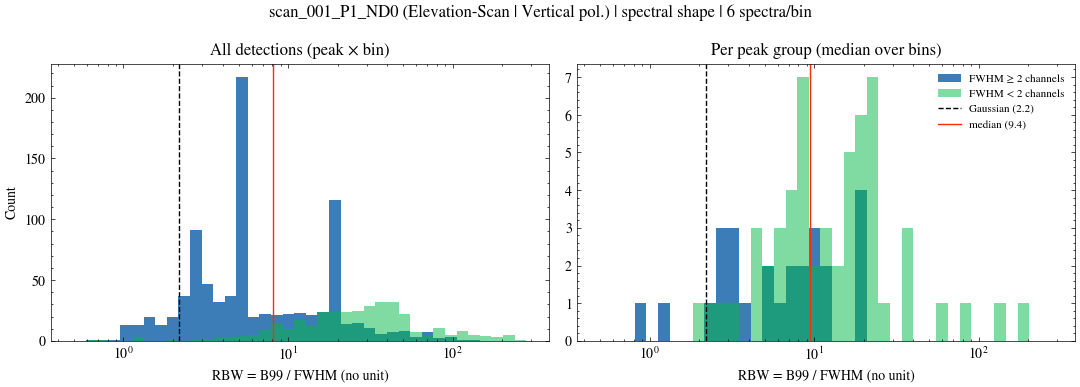

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
bins = np.logspace(np.log10(0.5), np.log10(max(ratio_det['RBW'].max(), 10) * 1.1), 40)

for ax, d, title in [(axes[0], ratio_det, 'All detections (peak × bin)'),
                     (axes[1], ratio_grp, 'Per peak group (median over bins)')]:
    ax.hist(d.loc[d['resolved'], 'RBW'], bins=bins, alpha=0.8, label='FWHM ≥ 2 channels')
    ax.hist(d.loc[~d['resolved'], 'RBW'], bins=bins, alpha=0.5, label='FWHM < 2 channels')
    ax.axvline(GAUSS_RATIO, color='k', ls='--', lw=1, label=f'Gaussian ({GAUSS_RATIO:.1f})')
    ax.axvline(d['RBW'].median(), color='C3', lw=1, label=f'median ({d["RBW"].median():.1f})')
    ax.set_xscale('log')
    ax.set_xlabel('RBW = B99 / FWHM (no unit)')
    ax.set_title(title)
axes[0].set_ylabel('Count')
axes[1].legend(fontsize=8)
fig.suptitle(f'{scan_name} ({scan_label}) | spectral shape | {BIN_SIZE} spectra/bin')
fig.tight_layout()

# if to_save:
#     full_path = os.path.join(dirname, scan_name)
#     os.makedirs(full_path, exist_ok=True)
#     fig.savefig(f'{dirname}/RBW_hist_{scan_name}.pdf', bbox_inches='tight')
#     fig.savefig(f'{dirname}/RBW_hist_{scan_name}.png', bbox_inches='tight')
# plt.show()


# Variation of x = [fc, B99, FWHM, B10, B20, B30, RBW, A, S] vs frequency

Each peak group is assigned to the frequency allocation that contains its reference frequency, using the same bands as `SKAMPI_RFI_PIPELINE/rfi_analysis_workflow.ipynb`. Where allocations overlap (UMTS DL inside Mobile Satellite, Air Traffic inside Weather Radar), the peak goes to the **narrowest** one. Peaks outside every allocation are labelled `Unallocated`.

Each peak is summarised by the median of each metric over the bins it was detected in. `fc` itself just tracks frequency, so it is replaced by `fc_std`, the temporal drift of the centre frequency in **kHz**. The `_cv` columns show how stable each metric is in time.

In [19]:
# Frequency allocations (GHz), as in SKAMPI_RFI_PIPELINE/rfi_analysis_workflow.ipynb
RFI_BANDS = {
    "Cellular GSM Uplink": (1.71, 1.785),
    "Cellular GSM Downlink": (1.805, 1.88),
    "DECT Phones": (1.88, 1.90),
    "UMTS Uplink": (1.92, 1.98),
    "UMTS Downlink": (2.11, 2.17),
    "Mobile Satellite": (2.00, 2.20),
    "Space Research / EESS": (2.20, 2.29),
    "IMT 2300 (4G/5G)": (2.30, 2.40),
    "Wi-Fi / Bluetooth (ISM)": (2.40, 2.483),
    "LTE / 5G (2600 band)": (2.50, 2.69),
    "Air Traffic Radar": (2.70, 2.90),
    "Weather Radar": (2.70, 3.00),
    "Microwave Backhaul": (3.00, 3.30),
    "5G NR (n78)": (3.30, 3.60),
}
TRANSITION_BANDS = {
    "Gap: GSM DL to GSM UL": (1.785, 1.805),
    "Gap: DECT to UMTS UL": (1.90, 1.92),
    "Gap: UMTS UL to MSS": (1.98, 2.00),
    "Gap: EESS to IMT-2300": (2.29, 2.30),
    "Gap: ISM to LTE 2600": (2.483, 2.50),
    "Gap: LTE 2600 to Radar": (2.69, 2.70),
}
ALL_BANDS = dict(sorted({**RFI_BANDS, **TRANSITION_BANDS}.items(), key=lambda kv: kv[1][0]))

def assign_band(f_khz):
    """Narrowest allocation containing f (so overlapping bands resolve to the most specific one)."""
    f_ghz = f_khz / 1e6
    hits = [(hi - lo, name) for name, (lo, hi) in ALL_BANDS.items() if lo <= f_ghz < hi]
    return min(hits)[1] if hits else 'Unallocated'

per_bin['band'] = per_bin['peak_reference_kHz'].map(assign_band)

In [20]:
MIN_BINS = 1   # only keep peak groups detected in at least this many bins

# fc only tracks frequency; its temporal drift (std over bins) is the informative quantity
FREQ_METRICS = ['fc_std', 'B99', 'FWHM', 'B10', 'B20', 'B30', 'RBW', 'A', 'S']
CV_METRICS = [m for m in METRICS if m != 'fc']

per_peak = (per_bin.groupby('peak_group')
            .agg(f_ref_kHz=('peak_reference_kHz', 'first'),
                 band=('band', 'first'),
                 detection_level=('detection_level', 'first'),
                 n_bins=('time_bin', 'nunique'),
                 fc_std=('fc', 'std'),
                 **{m: (m, 'median') for m in METRICS if m != 'fc'},
                 **{f'{m}_cv': (m, cv) for m in CV_METRICS})
            .query('n_bins >= @MIN_BINS')
            .sort_values('f_ref_kHz')
            .pipe(add_scan_info))

# bands in frequency order, only those with detections
BAND_ORDER = [b for b in [*ALL_BANDS, 'Unallocated'] if b in set(per_peak['band'])]

band_summary = (per_peak.groupby('band')
                .agg(n_peaks=('f_ref_kHz', 'size'),
                     n_high=('detection_level', lambda s: (s == 'high').sum()),
                     n_low=('detection_level', lambda s: (s == 'low').sum()),
                     **{m: (m, 'median') for m in FREQ_METRICS},
                     A_cv=('A_cv', 'median'),
                     B99_cv=('B99_cv', 'median'))
                .reindex(BAND_ORDER)
                .pipe(add_scan_info))
band_summary

,scan,scan_type,polarization,n_peaks,n_high,n_low,fc_std,B99,FWHM,B10,B20,B30,RBW,A,S,A_cv,B99_cv
band,,,,,,,,,,,,,,,,,
Cellular GSM Downlink,scan/001/P1_ND0,Elevation-Scan,Vertical,5,1,4,279.814439,1375.198364,48.191298,195.040712,991.632134,1443.881801,11.156656,1.287766e+11,0.647464,0.025292,0.036860
DECT Phones,scan/001/P1_ND0,Elevation-Scan,Vertical,1,0,1,174.366296,7823.944092,855.523961,5093.409181,7993.085088,7994.921743,8.748055,1.869544e+12,-0.015791,0.255212,0.296450
UMTS Uplink,scan/001/P1_ND0,Elevation-Scan,Vertical,1,0,1,NaN,4192.352295,220.283281,528.878728,4291.312147,4292.561963,19.031641,8.055755e+11,0.177565,NaN,NaN
Mobile Satellite,scan/001/P1_ND0,Elevation-Scan,Vertical,5,4,1,262.411304,3150.939941,65.771710,1429.434984,3173.557857,3653.941985,17.790221,7.167953e+11,0.011831,0.489801,0.432707
UMTS Downlink,scan/001/P1_ND0,Elevation-Scan,Vertical,4,2,2,418.740555,4005.432129,1012.934609,4037.298689,4242.006558,4274.779137,3.970775,2.248039e+12,-0.062125,0.526160,0.117819
Space Research / EESS,scan/001/P1_ND0,Elevation-Scan,Vertical,9,0,9,529.116884,720.977783,56.316539,280.874039,687.970353,764.457388,11.624827,1.669539e+11,0.015521,0.480041,0.451862
Gap: EESS to IMT-2300,scan/001/P1_ND0,Elevation-Scan,Vertical,2,0,2,725.356957,273.704529,47.189925,205.914293,337.912308,339.085502,6.110186,6.860985e+10,0.105422,0.496557,0.676363
IMT 2300 (4G/5G),scan/001/P1_ND0,Elevation-Scan,Vertical,18,1,17,942.211296,1001.358032,64.120845,461.573152,1039.727768,1072.482514,11.229891,3.394828e+11,-0.033631,0.354270,0.363016
Wi-Fi / Bluetooth (ISM),scan/001/P1_ND0,Elevation-Scan,Vertical,15,0,15,946.325692,640.869141,69.201079,315.042970,713.080692,714.482958,8.905734,2.382101e+11,-0.036511,0.621285,0.617120


In [21]:
# save the dataframes of metrics vs frequency
if to_save:
    os.makedirs(full_path, exist_ok=True)
    band_summary.to_csv(f'{full_path}/metrics_band_summary_{scan_name}.csv')
    per_peak.to_csv(f'{full_path}/metrics_per_peak_{scan_name}.csv')


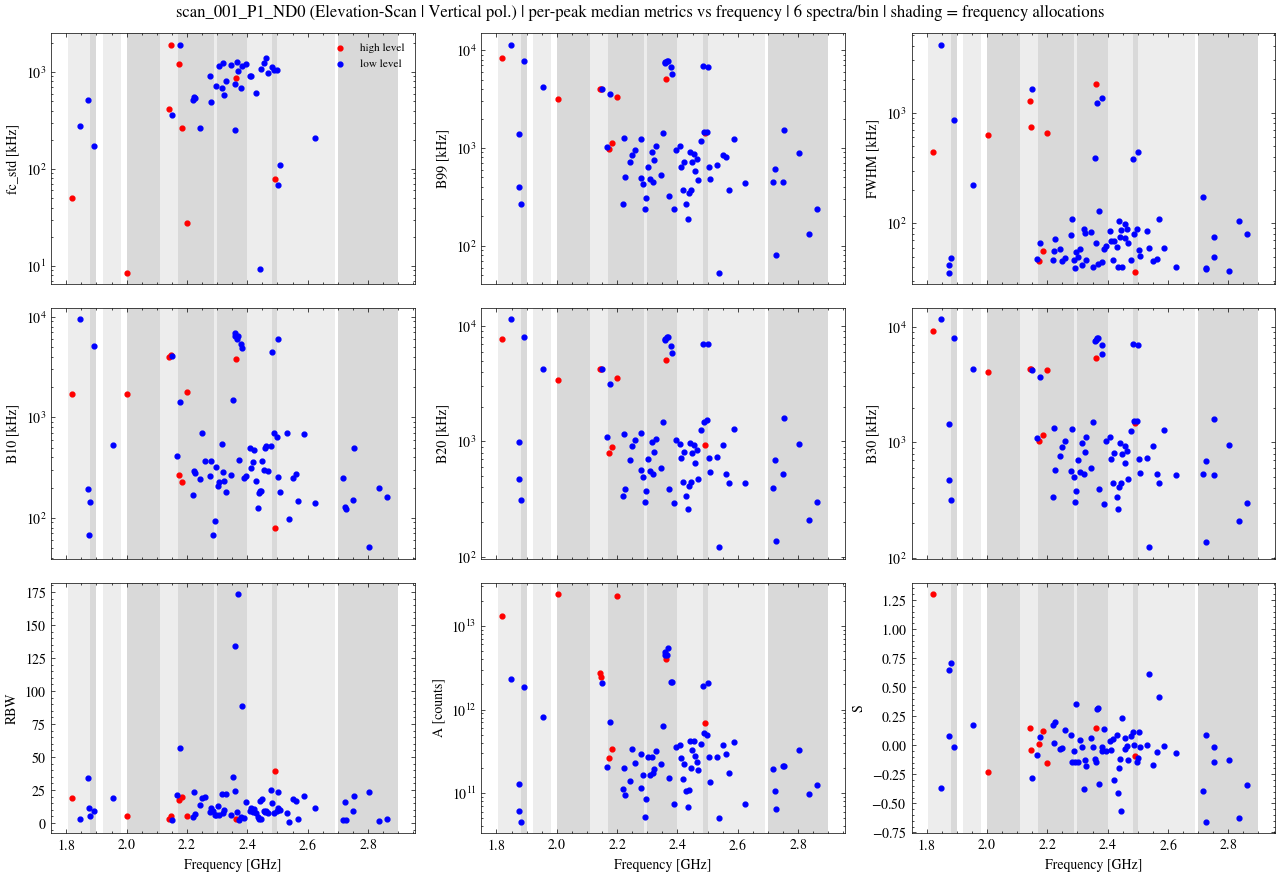

In [22]:
LOG_METRICS = {'fc_std', 'B99', 'FWHM', 'B10', 'B20', 'B30', 'A'}
LEVEL_COLOURS = {'high': 'r', 'low': 'b'}

def metric_unit(metric):
    return 'kHz' if metric in FREQUENCY_METRICS | {'fc_std'} else 'counts' if metric == 'A' else ''

def shade_bands(ax):
    """Alternate grey shading of the allocations that contain detections."""
    for k, name in enumerate(b for b in BAND_ORDER if b != 'Unallocated'):
        lo, hi = ALL_BANDS[name]
        ax.axvspan(lo, hi, color='0.85' if k % 2 else '0.93', zorder=0, lw=0)

fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, metric in zip(axes.flat, FREQ_METRICS):
    shade_bands(ax)
    for level, d in per_peak.groupby('detection_level'):
        ax.scatter(d['f_ref_kHz'] / 1e6, d[metric], s=12, color=LEVEL_COLOURS[level],
                   label=f'{level} level', zorder=3)
    if metric in LOG_METRICS:
        ax.set_yscale('log')
    unit = metric_unit(metric)
    ax.set_ylabel(f'{metric} [{unit}]' if unit else metric)
for ax in axes[-1]:
    ax.set_xlabel('Frequency [GHz]')
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'{scan_name} ({scan_label}) | per-peak median metrics vs frequency | '
             f'{BIN_SIZE} spectra/bin | shading = frequency allocations')
fig.tight_layout()

# if to_save:
#     os.makedirs(dirname, exist_ok=True)
#     fig.savefig(f'{dirname}/metrics_vs_frequency_{scan_name}.pdf', bbox_inches='tight')
#     fig.savefig(f'{dirname}/metrics_vs_frequency_{scan_name}.png', bbox_inches='tight')
# plt.show()

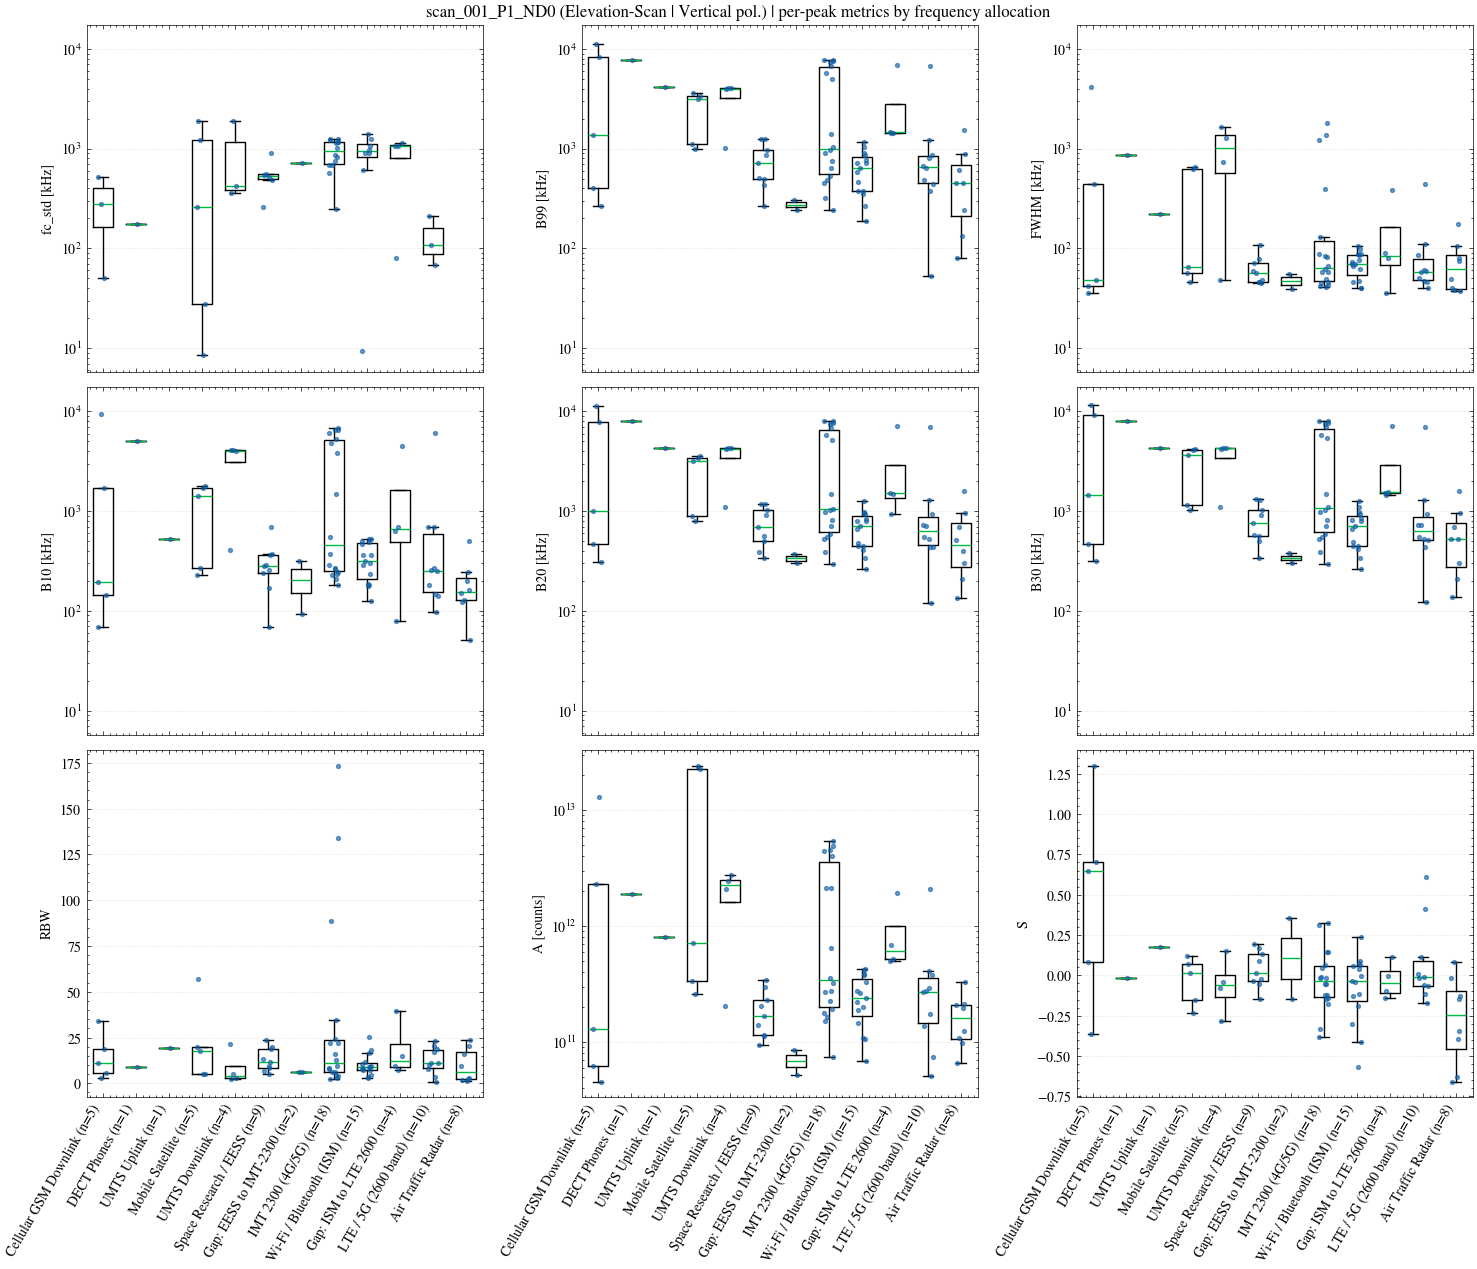

In [23]:
# distribution of each metric per band (one point per peak group)

# shared y-range for every metric measured in kHz, so their panels can be compared directly
KHZ_METRICS = [m for m in FREQ_METRICS if metric_unit(m) == 'kHz']
khz_values = per_peak[KHZ_METRICS].to_numpy().ravel()
khz_values = khz_values[np.isfinite(khz_values) & (khz_values > 0)]   # > 0 because of the log axis
KHZ_YLIM = (khz_values.min() / 1.5, khz_values.max() * 1.5)



fig, axes = plt.subplots(3, 3, figsize=(15, 13), sharex=True)
positions = np.arange(len(BAND_ORDER))
for ax, metric in zip(axes.flat, FREQ_METRICS):
    values = [per_peak.loc[per_peak['band'] == b, metric].dropna() for b in BAND_ORDER]
    ax.boxplot(values, positions=positions, widths=0.6, showfliers=False)
    for x, d in zip(positions, values):
        jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(d))
        ax.scatter(x + jitter, d, s=8, color='C0', alpha=0.6, zorder=3)
    if metric in LOG_METRICS:
        if metric in LOG_METRICS:
            ax.set_yscale('log')
        if metric in KHZ_METRICS:
            ax.set_ylim(KHZ_YLIM)


    unit = metric_unit(metric)
    ax.set_ylabel(f'{metric} [{unit}]' if unit else metric)
    ax.grid(True, axis='y', ls=':', lw=0.5, alpha=0.5)
n_per_band = per_peak['band'].value_counts()
for ax in axes[-1]:
    ax.set_xticks(positions)
    ax.set_xticklabels([f'{b} (n={n_per_band[b]})' for b in BAND_ORDER], rotation=60, ha='right')
    #ax.set_
fig.suptitle(f'{scan_name} ({scan_label}) | per-peak metrics by frequency allocation')
fig.tight_layout()

if to_save:
    os.makedirs(full_path, exist_ok=True)
    fig.savefig(f'{full_path}/metrics_by_band_{scan_name}.pdf', bbox_inches='tight')
    fig.savefig(f'{full_path}/metrics_by_band_{scan_name}.png', bbox_inches='tight')
plt.show()

Do the bands differ? Kruskal–Wallis test per metric across bands with at least `MIN_PEAKS_TEST` peaks. A small p-value means at least one band's distribution differs from the others. With only a few peaks per band, treat this as indicative.

In [24]:
from scipy.stats import kruskal

MIN_PEAKS_TEST = 3
test_bands = [b for b in BAND_ORDER if (per_peak['band'] == b).sum() >= MIN_PEAKS_TEST]

rows = []
for metric in FREQ_METRICS + [f'{m}_cv' for m in CV_METRICS]:
    groups_ = [per_peak.loc[per_peak['band'] == b, metric].dropna() for b in test_bands]
    groups_ = [g for g in groups_ if len(g) >= MIN_PEAKS_TEST]
    if len(groups_) >= 2:
        H, p = kruskal(*groups_)
        rows.append({'metric': metric, 'n_bands': len(groups_), 'H': H, 'p_value': p})

band_test = pd.DataFrame(rows).sort_values('p_value').pipe(add_scan_info)
print(f"Bands tested (>= {MIN_PEAKS_TEST} peaks): {test_bands}")
band_test

Bands tested (>= 3 peaks): ['Cellular GSM Downlink', 'Mobile Satellite', 'UMTS Downlink', 'Space Research / EESS', 'IMT 2300 (4G/5G)', 'Wi-Fi / Bluetooth (ISM)', 'Gap: ISM to LTE 2600', 'LTE / 5G (2600 band)', 'Air Traffic Radar']


,scan,scan_type,polarization,metric,n_bands,H,p_value
1,scan/001/P1_ND0,Elevation-Scan,Vertical,B99,9,23.901151,0.002381
5,scan/001/P1_ND0,Elevation-Scan,Vertical,B30,9,23.812263,0.002464
7,scan/001/P1_ND0,Elevation-Scan,Vertical,A,9,22.623548,0.003883
4,scan/001/P1_ND0,Elevation-Scan,Vertical,B20,9,21.738635,0.005424
3,scan/001/P1_ND0,Elevation-Scan,Vertical,B10,9,18.874970,0.015543
11,scan/001/P1_ND0,Elevation-Scan,Vertical,B10_cv,8,15.556859,0.029488
0,scan/001/P1_ND0,Elevation-Scan,Vertical,fc_std,8,13.001771,0.072065
12,scan/001/P1_ND0,Elevation-Scan,Vertical,B20_cv,8,12.816658,0.076704
9,scan/001/P1_ND0,Elevation-Scan,Vertical,B99_cv,8,12.776285,0.077750
13,scan/001/P1_ND0,Elevation-Scan,Vertical,B30_cv,8,12.089619,0.097650


In [25]:
# # Save the result tables (one CSV per table, tagged with the scan name)
# tables = {
#     'results_binned': results_binned,   # every peak in every bin
#     'occupancy': occupancy,
#     'variation': variation,
#     'res_full': res_full,               # peaks in the time-averaged spectrum
#     'ratio_grp': ratio_grp,
#     'per_peak': per_peak,
#     'band_summary': band_summary,
#     'band_test': band_test,
# }

# out_dir = os.path.join(dirname, 'tables')
# os.makedirs(out_dir, exist_ok=True)

# for name, df in tables.items():
#     df = df.copy()
#     if isinstance(df.columns, pd.MultiIndex):   # variation: ('B99', 'mean') -> 'B99_mean'
#         df.columns = ['_'.join(c for c in col if c) for col in df.columns]
#     df.to_csv(os.path.join(out_dir, f'{name}_{scan_name}.csv'))

# print(f"Saved {len(tables)} tables to {out_dir}/")
